<a href="https://colab.research.google.com/github/harshithaabollineni/DLAC/blob/main/VisionPort_Traffic_Monitoring_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics opencv-python-headless numpy matplotlib

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ultralytics
import os
import time

from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Image

print("OpenCV Version:", cv2.__version__)
print("Ultralytics Version:", ultralytics.__version__)
print("VisionPort Environment Ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OpenCV Version: 4.14.0
Ultralytics Version: 8.4.215
VisionPort Environment Ready!


In [ ]:
from IPython.display import Javascript, display
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="traffic.jpg"):
    js = Javascript('''
    async function takePhoto() {
        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        button.textContent = 'Capture Photo';
        div.appendChild(video);
        div.appendChild(button);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg');
    }
    ''')

    display(js)
    data = eval_js("takePhoto()")
    image_data = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(image_data)

    print("Traffic image captured successfully!")

take_photo()

<IPython.core.display.Javascript object>

Traffic image captured successfully!


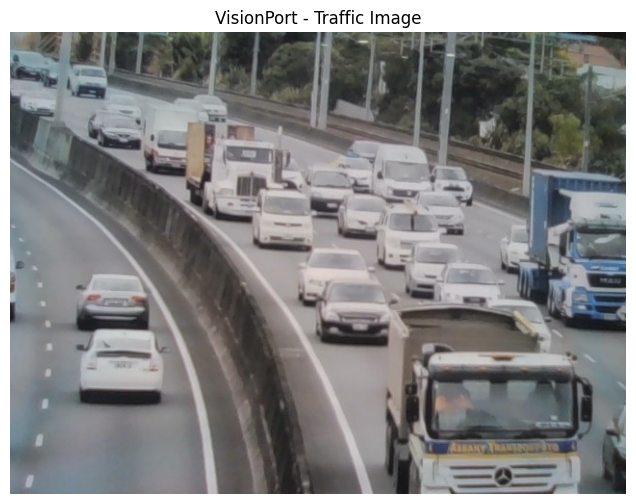

In [ ]:
image = cv2.imread("traffic.jpg")

if image is not None:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 6))
    plt.imshow(image_rgb)
    plt.title("VisionPort - Traffic Image")
    plt.axis("off")
    plt.show()
else:
    print("Image not found!")

In [ ]:
uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Uploaded Video:", video_path)

Saving Traffic.mp4 to Traffic.mp4
Uploaded Video: Traffic.mp4


In [ ]:
from IPython.display import Video, display

display(Video(video_path, embed=True))

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import time

from ultralytics import YOLO
from google.colab import files

print("All libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)

print("VisionPort is ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!
OpenCV Version: 4.14.0
VisionPort is ready!


In [ ]:
from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Video uploaded successfully!")
print("Video path:", video_path)

Saving Traffic.mp4 to Traffic.mp4
Video uploaded successfully!
Video path: Traffic.mp4


In [ ]:
import cv2

cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    print("Video opened successfully!")
    print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
else:
    print("Unable to open video!")

cap.release()

Video opened successfully!
Total frames: 660


In [ ]:
import os

cap = cv2.VideoCapture(video_path)

os.makedirs("traffic_frames", exist_ok=True)

frame_count = 0
saved_count = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % 30 == 0:

        filename = f"traffic_frames/frame_{frame_count}.jpg"

        cv2.imwrite(filename, frame)

        saved_count += 1

    frame_count += 1

cap.release()

print("Total frames processed:", frame_count)
print("Frames extracted:", saved_count)
print("Frames extracted successfully!")

Total frames processed: 660
Frames extracted: 22
Frames extracted successfully!


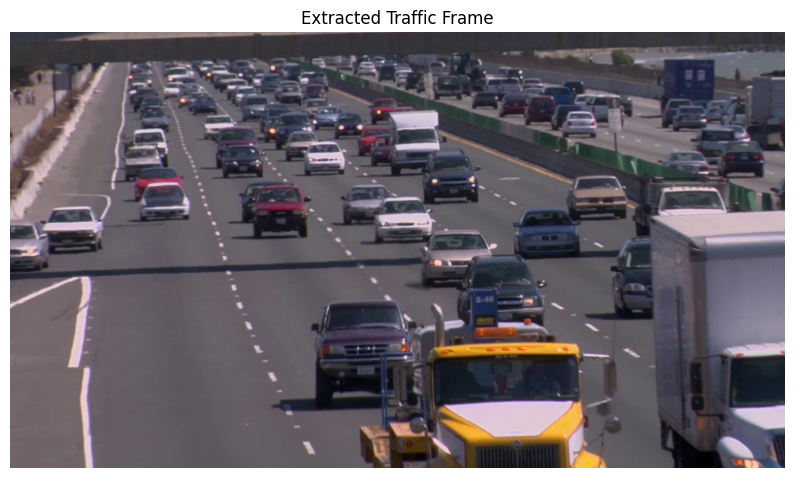

In [ ]:
sample_frame = cv2.imread("traffic_frames/frame_0.jpg")

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(sample_frame, cv2.COLOR_BGR2RGB))
plt.title("Extracted Traffic Frame")
plt.axis("off")
plt.show()

In [ ]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!



image 1/1 /content/traffic_frames/frame_0.jpg: 384x640 15 cars, 9.2ms
Speed: 109.0ms preprocess, 9.2ms inference, 73.6ms postprocess per image at shape (1, 3, 384, 640)


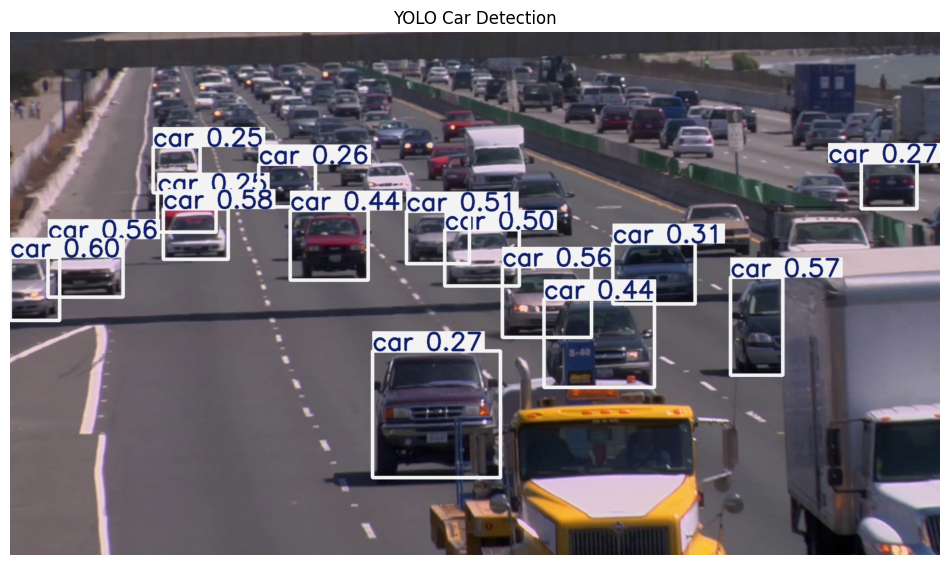

In [ ]:
results = model.predict(
    source="traffic_frames/frame_0.jpg",
    conf=0.25,
    classes=[2]
)

car_image = results[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(car_image, cv2.COLOR_BGR2RGB))
plt.title("YOLO Car Detection")
plt.axis("off")
plt.show()


image 1/1 /content/traffic_frames/frame_0.jpg: 384x640 15 cars, 4 trucks, 9.4ms
Speed: 1.9ms preprocess, 9.4ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


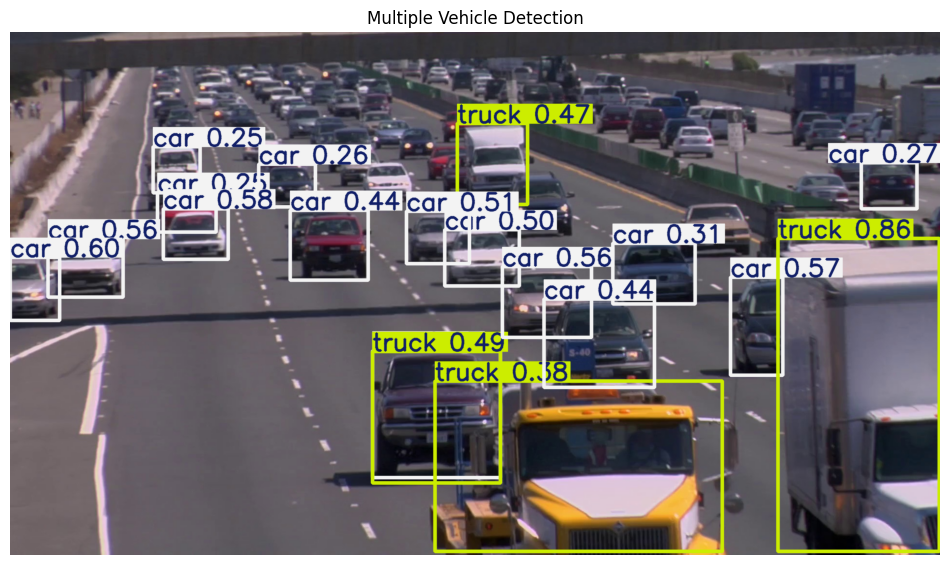

In [ ]:
vehicle_classes = [2, 3, 5, 7]

results = model.predict(
    source="traffic_frames/frame_0.jpg",
    conf=0.25,
    classes=vehicle_classes
)

vehicle_image = results[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(vehicle_image, cv2.COLOR_BGR2RGB))
plt.title("Multiple Vehicle Detection")
plt.axis("off")
plt.show()

In [ ]:
results = model.predict(
    source="traffic_frames/frame_0.jpg",
    conf=0.25,
    classes=[2, 3, 5, 7]
)

for result in results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        vehicle_name = model.names[class_id]

        print(
            "Vehicle:", vehicle_name,
            "| Confidence:", round(confidence * 100, 2), "%"
        )


image 1/1 /content/traffic_frames/frame_0.jpg: 384x640 15 cars, 4 trucks, 9.3ms
Speed: 1.8ms preprocess, 9.3ms inference, 1.8ms postprocess per image at shape (1, 3, 384, 640)
Vehicle: truck | Confidence: 85.66 %
Vehicle: car | Confidence: 60.45 %
Vehicle: car | Confidence: 58.27 %
Vehicle: car | Confidence: 56.61 %
Vehicle: car | Confidence: 56.44 %
Vehicle: car | Confidence: 55.56 %
Vehicle: car | Confidence: 51.46 %
Vehicle: car | Confidence: 49.52 %
Vehicle: truck | Confidence: 49.27 %
Vehicle: truck | Confidence: 46.76 %
Vehicle: car | Confidence: 44.47 %
Vehicle: car | Confidence: 43.63 %
Vehicle: truck | Confidence: 37.98 %
Vehicle: car | Confidence: 31.1 %
Vehicle: car | Confidence: 26.97 %
Vehicle: car | Confidence: 26.8 %
Vehicle: car | Confidence: 25.94 %
Vehicle: car | Confidence: 25.24 %
Vehicle: car | Confidence: 25.0 %


In [ ]:
results = model.predict(
    source="traffic_frames/frame_0.jpg",
    conf=0.25,
    classes=[2, 3, 5, 7]
)

vehicle_count = 0

for result in results:
    vehicle_count = len(result.boxes)

print("Total Vehicles Detected:", vehicle_count)


image 1/1 /content/traffic_frames/frame_0.jpg: 384x640 15 cars, 4 trucks, 11.4ms
Speed: 2.5ms preprocess, 11.4ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)
Total Vehicles Detected: 19


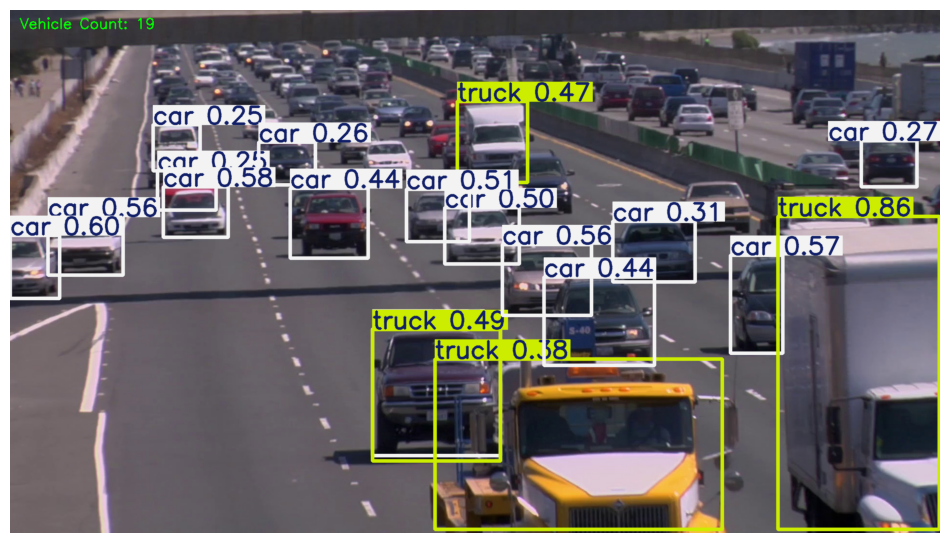

In [ ]:
count_image = results[0].plot()

cv2.putText(
    count_image,
    f"Vehicle Count: {vehicle_count}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 0),
    2
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(count_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
if vehicle_count <= 5:
    density = "LOW"

elif vehicle_count <= 15:
    density = "MEDIUM"

else:
    density = "HIGH"

print("Vehicle Count:", vehicle_count)
print("Traffic Density:", density)

Vehicle Count: 19
Traffic Density: HIGH


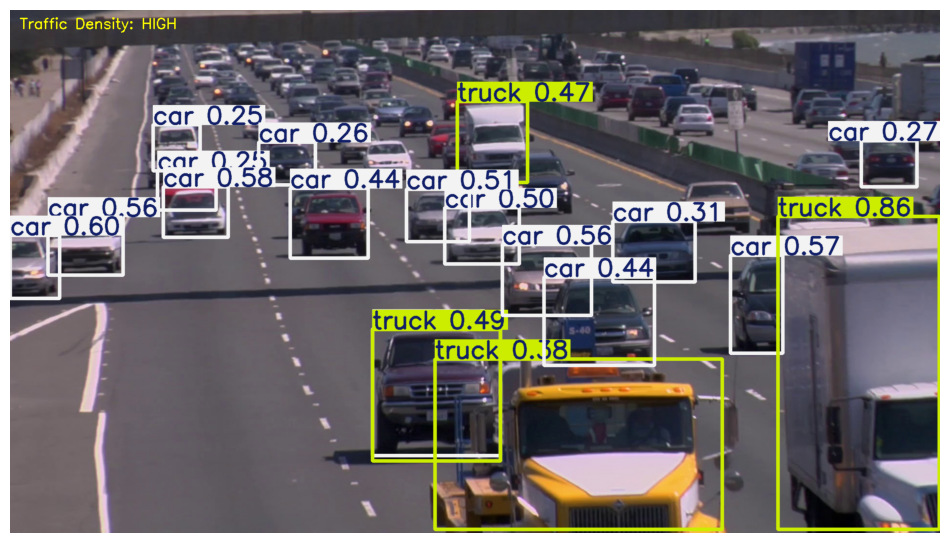

In [ ]:
density_image = results[0].plot()

cv2.putText(
    density_image,
    f"Traffic Density: {density}",
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 255),
    2
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(density_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

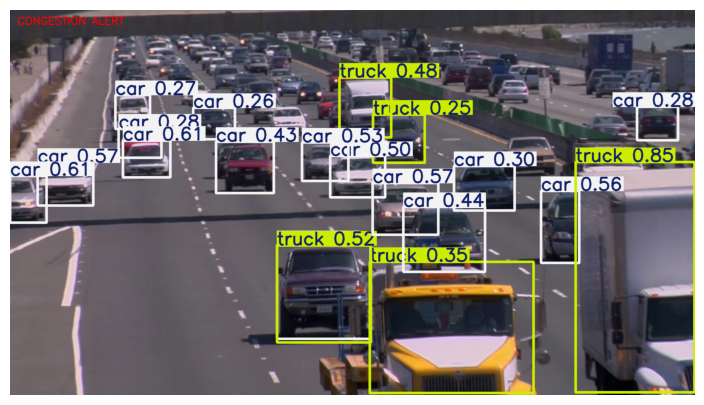

Congestion detection completed.


In [ ]:
cap = cv2.VideoCapture(video_path)

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        frame,
        conf=0.25,
        classes=[2, 3, 5, 7],
        verbose=False
    )

    count = len(results[0].boxes)

    if count <= 5:
        status = "LOW TRAFFIC"
    elif count <= 15:
        status = "MODERATE TRAFFIC"
    else:
        status = "CONGESTION ALERT"

    output = results[0].plot()

    cv2.putText(
        output,
        status,
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        2
    )

    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    break

cap.release()

print("Congestion detection completed.")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 692ms
Prepared 1 package in 25ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



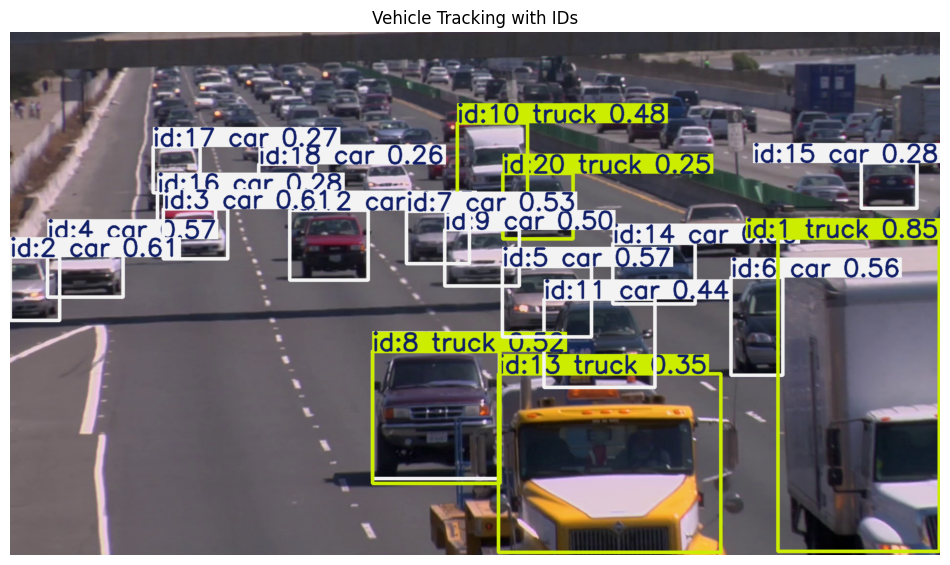

In [ ]:
cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

if ret:
    tracking_results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    tracking_image = tracking_results[0].plot()

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(tracking_image, cv2.COLOR_BGR2RGB))
    plt.title("Vehicle Tracking with IDs")
    plt.axis("off")
    plt.show()

cap.release()

In [ ]:
import math

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

# Replace this with a measured calibration value
PIXELS_PER_METER = 20

previous_positions = {}
frame_number = 0

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:
        for box, track_id in zip(boxes, boxes.id):
            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2

            if track_id in previous_positions:
                px, py = previous_positions[track_id]

                distance_pixels = math.hypot(
                    cx - px, cy - py
                )

                distance_meters = (
                    distance_pixels / PIXELS_PER_METER
                )

                speed = distance_meters * fps * 3.6

                print(
                    "Vehicle ID:", track_id,
                    "Approx Speed:", round(speed, 2), "km/h"
                )

            previous_positions[track_id] = (cx, cy)

    if frame_number >= 100:
        break

cap.release()

Vehicle ID: 1 Approx Speed: 27.63 km/h
Vehicle ID: 2 Approx Speed: 15.56 km/h
Vehicle ID: 3 Approx Speed: 4.32 km/h
Vehicle ID: 4 Approx Speed: 17.79 km/h
Vehicle ID: 5 Approx Speed: 22.01 km/h
Vehicle ID: 6 Approx Speed: 28.95 km/h
Vehicle ID: 7 Approx Speed: 9.65 km/h
Vehicle ID: 8 Approx Speed: 17.79 km/h
Vehicle ID: 9 Approx Speed: 9.65 km/h
Vehicle ID: 10 Approx Speed: 17.79 km/h
Vehicle ID: 11 Approx Speed: 27.63 km/h
Vehicle ID: 12 Approx Speed: 13.65 km/h
Vehicle ID: 13 Approx Speed: 141.96 km/h
Vehicle ID: 14 Approx Speed: 21.58 km/h
Vehicle ID: 15 Approx Speed: 13.65 km/h
Vehicle ID: 17 Approx Speed: 0.0 km/h
Vehicle ID: 18 Approx Speed: 9.65 km/h
Vehicle ID: 19 Approx Speed: 17.79 km/h
Vehicle ID: 1 Approx Speed: 15.56 km/h
Vehicle ID: 2 Approx Speed: 19.3 km/h
Vehicle ID: 3 Approx Speed: 8.63 km/h
Vehicle ID: 4 Approx Speed: 19.3 km/h
Vehicle ID: 5 Approx Speed: 27.29 km/h
Vehicle ID: 6 Approx Speed: 45.06 km/h
Vehicle ID: 7 Approx Speed: 19.3 km/h
Vehicle ID: 8 Approx Spee

In [ ]:
image = cv2.imread("traffic_frames/frame_0.jpg")

if image is not None:
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    red_lower1 = np.array([0, 100, 100])
    red_upper1 = np.array([10, 255, 255])

    red_lower2 = np.array([160, 100, 100])
    red_upper2 = np.array([180, 255, 255])

    yellow_lower = np.array([15, 100, 100])
    yellow_upper = np.array([35, 255, 255])

    green_lower = np.array([40, 50, 50])
    green_upper = np.array([90, 255, 255])

    red_mask = (
        cv2.inRange(hsv, red_lower1, red_upper1) |
        cv2.inRange(hsv, red_lower2, red_upper2)
    )

    yellow_mask = cv2.inRange(
        hsv, yellow_lower, yellow_upper
    )

    green_mask = cv2.inRange(
        hsv, green_lower, green_upper
    )

    red_pixels = cv2.countNonZero(red_mask)
    yellow_pixels = cv2.countNonZero(yellow_mask)
    green_pixels = cv2.countNonZero(green_mask)

    if max(red_pixels, yellow_pixels, green_pixels) < 20:
        signal_status = "SIGNAL NOT DETECTED"
    elif red_pixels > yellow_pixels and red_pixels > green_pixels:
        signal_status = "RED"
    elif yellow_pixels > red_pixels and yellow_pixels > green_pixels:
        signal_status = "YELLOW"
    else:
        signal_status = "GREEN"

    print("Traffic Signal Status:", signal_status)
else:
    print("Error: Could not load the traffic frame. Please check if 'traffic_frames/frame_0.jpg' exists.")

Traffic Signal Status: YELLOW


In [ ]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 30

stationary_since = {}
previous_positions = {}

frame_number = 0

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1
    current_time = frame_number / fps

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:
        for box, track_id in zip(boxes, boxes.id):

            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2

            if track_id in previous_positions:

                px, py = previous_positions[track_id]

                movement = math.hypot(cx - px, cy - py)

                if movement < 5:

                    if track_id not in stationary_since:
                        stationary_since[track_id] = current_time

                    waiting_time = (
                        current_time - stationary_since[track_id]
                    )

                    print(
                        "Vehicle ID:", track_id,
                        "Waiting Time:",
                        round(waiting_time, 2), "seconds"
                    )

                else:
                    stationary_since.pop(track_id, None)

            previous_positions[track_id] = (cx, cy)

    if frame_number >= int(fps * 20):
        break

cap.release()

Vehicle ID: 18 Waiting Time: 0.0 seconds
Vehicle ID: 18 Waiting Time: 0.04 seconds
Vehicle ID: 29 Waiting Time: 0.0 seconds
Vehicle ID: 179 Waiting Time: 0.0 seconds
Vehicle ID: 180 Waiting Time: 0.0 seconds
Vehicle ID: 181 Waiting Time: 0.0 seconds
Vehicle ID: 184 Waiting Time: 0.0 seconds
Vehicle ID: 185 Waiting Time: 0.0 seconds
Vehicle ID: 187 Waiting Time: 0.0 seconds
Vehicle ID: 188 Waiting Time: 0.0 seconds
Vehicle ID: 193 Waiting Time: 0.0 seconds
Vehicle ID: 101 Waiting Time: 0.0 seconds
Vehicle ID: 29 Waiting Time: 0.04 seconds
Vehicle ID: 180 Waiting Time: 0.04 seconds
Vehicle ID: 185 Waiting Time: 0.04 seconds
Vehicle ID: 188 Waiting Time: 0.04 seconds
Vehicle ID: 101 Waiting Time: 0.04 seconds
Vehicle ID: 195 Waiting Time: 0.0 seconds
Vehicle ID: 7 Waiting Time: 0.0 seconds
Vehicle ID: 29 Waiting Time: 0.08 seconds
Vehicle ID: 179 Waiting Time: 0.0 seconds
Vehicle ID: 180 Waiting Time: 0.08 seconds
Vehicle ID: 184 Waiting Time: 0.0 seconds
Vehicle ID: 185 Waiting Time: 0.0

In [ ]:
cap = cv2.VideoCapture(video_path)

ret, first_frame = cap.read()

height, width = first_frame.shape[:2]

LINE_Y = height // 2

previous_y = {}
count_entering = 0
count_leaving = 0

cap.release()

cap = cv2.VideoCapture(video_path)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        for box, track_id in zip(boxes, boxes.id):

            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            cy = (y1 + y2) // 2

            if track_id in previous_y:

                old_y = previous_y[track_id]

                if old_y < LINE_Y and cy >= LINE_Y:
                    count_entering += 1

                elif old_y > LINE_Y and cy <= LINE_Y:
                    count_leaving += 1

            previous_y[track_id] = cy

    if len(previous_y) > 0 and count_entering + count_leaving > 0:
        pass

print("Vehicles Entering:", count_entering)
print("Vehicles Leaving:", count_leaving)

cap.release()

Vehicles Entering: 51
Vehicles Leaving: 0


In [ ]:
cap = cv2.VideoCapture(video_path)

trajectories = {}
reported_turns = set()

# Change this according to the permitted route.
ALLOWED_TURN = "straight"

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        for box, track_id in zip(boxes, boxes.id):

            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            center = (
                (x1 + x2) // 2,
                (y1 + y2) // 2
            )

            trajectories.setdefault(track_id, []).append(center)

            points = trajectories[track_id]

            if len(points) >= 10 and track_id not in reported_turns:

                p1 = np.array(points[-10], dtype=float)
                p2 = np.array(points[-5], dtype=float)
                p3 = np.array(points[-1], dtype=float)

                v1 = p2 - p1
                v2 = p3 - p2

                if np.linalg.norm(v1) > 0 and np.linalg.norm(v2) > 0:

                    cosine = np.dot(v1, v2) / (
                        np.linalg.norm(v1) * np.linalg.norm(v2)
                    )

                    angle = math.degrees(
                        math.acos(np.clip(cosine, -1, 1))
                    )

                    if angle > 45 and ALLOWED_TURN == "straight":

                        print(
                            "Possible Wrong Turn:",
                            "Vehicle ID", track_id
                        )

                        reported_turns.add(track_id)

    if len(reported_turns) >= 5:
        break

cap.release()

print("Wrong-turn monitoring completed.")

Possible Wrong Turn: Vehicle ID 1462
Possible Wrong Turn: Vehicle ID 1535
Possible Wrong Turn: Vehicle ID 1606
Possible Wrong Turn: Vehicle ID 1603
Possible Wrong Turn: Vehicle ID 1632
Wrong-turn monitoring completed.


In [ ]:
cap = cv2.VideoCapture(video_path)

previous_positions = {}
wrong_way_ids = set()

# Expected movement: downward in the image.
EXPECTED_DIRECTION = np.array([0.0, 1.0])

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        for box, track_id in zip(boxes, boxes.id):

            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            center = np.array([
                (x1 + x2) // 2,
                (y1 + y2) // 2
            ])

            if track_id in previous_positions:

                movement = center - previous_positions[track_id]

                if np.linalg.norm(movement) > 5:

                    direction_score = np.dot(
                        movement, EXPECTED_DIRECTION
                    )

                    if direction_score < 0:
                        wrong_way_ids.add(track_id)

            previous_positions[track_id] = center

    if len(wrong_way_ids) >= 5:
        break

cap.release()

print("Wrong Direction Vehicle IDs:", wrong_way_ids)

for track_id in wrong_way_ids:
    print("WRONG WAY ALERT - Vehicle ID:", track_id)

Wrong Direction Vehicle IDs: {1760, 1834, 1837, 1752, 1791}
WRONG WAY ALERT - Vehicle ID: 1760
WRONG WAY ALERT - Vehicle ID: 1834
WRONG WAY ALERT - Vehicle ID: 1837
WRONG WAY ALERT - Vehicle ID: 1752
WRONG WAY ALERT - Vehicle ID: 1791


In [ ]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 30

ret, first_frame = cap.read()

height, width = first_frame.shape[:2]

# Example restricted area.
# Adjust these coordinates according to your video.
ROI = (
    width // 4,
    height // 4,
    3 * width // 4,
    3 * height // 4
)

cap.release()
cap = cv2.VideoCapture(video_path)

previous_positions = {}
stationary_start = {}

PARKING_LIMIT = 10

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        for box, track_id in zip(boxes, boxes.id):

            track_id = int(track_id)

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].tolist()
            )

            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2

            rx1, ry1, rx2, ry2 = ROI

            inside_roi = (
                rx1 <= cx <= rx2 and
                ry1 <= cy <= ry2
            )

            if inside_roi:

                if track_id in previous_positions:

                    px, py = previous_positions[track_id]

                    movement = math.hypot(cx - px, cy - py)

                    if movement < 5:

                        stationary_start.setdefault(
                            track_id, time.time()
                        )

                        duration = (
                            time.time() -
                            stationary_start[track_id]
                        )

                        if duration >= PARKING_LIMIT:
                            print(
                                "Possible Illegal Parking:",
                                "Vehicle ID", track_id
                            )

                    else:
                        stationary_start.pop(track_id, None)

            else:
                stationary_start.pop(track_id, None)

            previous_positions[track_id] = (cx, cy)

cap.release()

print("Restricted-area monitoring completed.")

Restricted-area monitoring completed.


Triple Riding Vehicles: 0


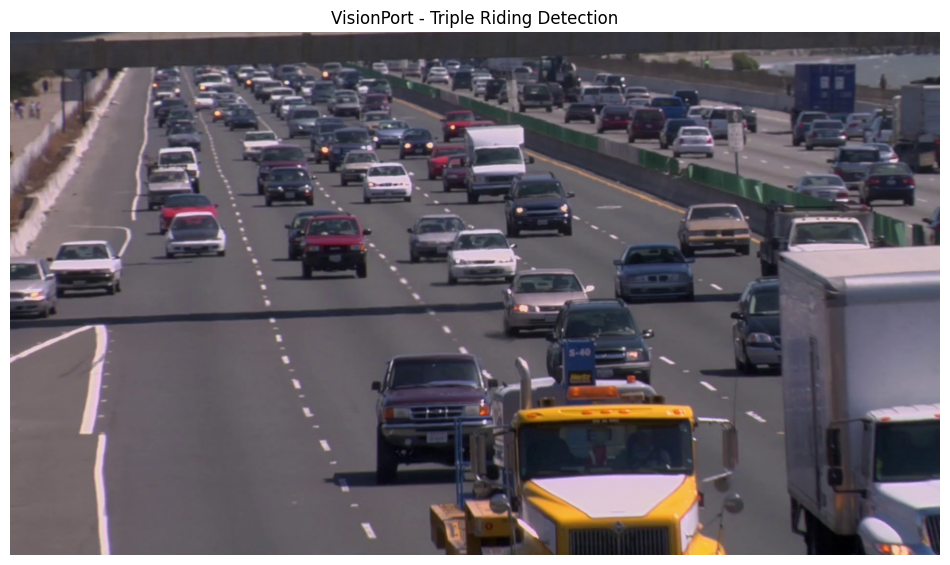

In [ ]:
image = cv2.imread("traffic_frames/frame_0.jpg")

if image is not None:
    results = model.predict(
        image,
        conf=0.25,
        classes=[0, 3],
        verbose=False
    )

    boxes = results[0].boxes

    persons = []
    motorcycles = []

    for box in boxes:

        class_id = int(box.cls[0])

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        if class_id == 0:
            persons.append((x1, y1, x2, y2))

        elif class_id == 3:
            motorcycles.append((x1, y1, x2, y2))

    triple_riding_count = 0

    output = image.copy()

    for bike in motorcycles:

        bx1, by1, bx2, by2 = bike

        person_count = 0

        for person in persons:

            px1, py1, px2, py2 = person

            center_x = (px1 + px2) // 2
            center_y = (py1 + py2) // 2

            if (
                bx1 <= center_x <= bx2 and
                by1 <= center_y <= by2
            ):
                person_count += 1

        if person_count > 2:

            triple_riding_count += 1

            label = "TRIPLE RIDING ALERT"

            color = (0, 0, 255)

        else:

            label = f"Persons: {person_count}"

            color = (0, 255, 0)

        cv2.rectangle(
            output,
            (bx1, by1),
            (bx2, by2),
            color,
            2
        )

        cv2.putText(
            output,
            label,
            (bx1, max(20, by1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            color,
            2
        )

    print("Triple Riding Vehicles:", triple_riding_count)

    plt.figure(figsize=(12, 7))
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.title("VisionPort - Triple Riding Detection")
    plt.axis("off")
    plt.show()
else:
    print("Error: Could not load the traffic frame. Please check if 'traffic_frames/frame_0.jpg' exists.")

In [ ]:
import shutil

shutil.make_archive(
    "VisionPort_Traffic_Frames",
    "zip",
    "traffic_frames"
)

files.download("VisionPort_Traffic_Frames.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

if os.path.exists("traffic_frames/frame_0.jpg"):
    files.download("traffic_frames/frame_0.jpg")
else:
    print("Error: traffic_frames/frame_0.jpg not found!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import shutil

os.makedirs("VisionPort_Results", exist_ok=True)

# Check and copy the extracted traffic frame if traffic.jpg doesn't exist
if os.path.exists("traffic.jpg"):
    shutil.copy(
        "traffic.jpg",
        "VisionPort_Results/traffic.jpg"
    )
elif os.path.exists("traffic_frames/frame_0.jpg"):
    shutil.copy(
        "traffic_frames/frame_0.jpg",
        "VisionPort_Results/traffic.jpg"
    )

if os.path.exists("traffic_frames"):
    shutil.copytree(
        "traffic_frames",
        "VisionPort_Results/traffic_frames",
        dirs_exist_ok=True
    )

print("VisionPort results saved successfully!")

VisionPort results saved successfully!
